# Hill climbing for the CVRPTW

**CesiCDP project team** · Solution method: hill climbing (one of the four methods compared by the team, with ant colony optimization and a genetic algorithm)

The modeling deliverable showed that our routing problem is NP-hard, so exact methods cannot handle realistic instances. This notebook builds a **hill-climbing** method step by step, measures how good its routes are on the Solomon benchmark, and explains where it works and where it struggles.

**Problem solved here: CVRPTW** (level A of the project). Trucks of capacity $Q$ leave a depot, serve every customer exactly once inside its time window (waiting is allowed if a truck arrives early) and come back before the depot closes; at most $k$ trucks may be used. As in the benchmark, the travel time between two points equals their Euclidean distance, and we minimize the **total distance**.

**Storyline**
1. The method: from plain hill climbing to Iterated Local Search
2. Implementation
3. Demonstration on one instance
4. Experimental study on the 56 Solomon instances
5. Strengths, limitations and improvements

## 1. The method

### 1.1 Hill climbing in one sentence
Start from a solution, look at small changes to it (the **neighbourhood**), apply a change whenever it makes the solution better, and stop when no small change helps. The solution reached is a **local optimum**: no neighbour is better, but a better solution may exist further away.

### 1.2 Solution and cost
- A **solution** is a list of routes, each route a list of customers, e.g. `[[5, 3, 7], [2, 1]]` (the depot is implicit at both ends).
- It is **feasible** if every customer appears once, every route carries at most $Q$, and every service starts inside its time window $[a_i, b_i]$, with the truck back at the depot before it closes.
- **Cost** = total distance $+\ 10\,000 \times$ (number of routes above $k$). The penalty lets the search start with too many trucks and pushes it to remove routes, which matches constraint (C3) of our ILP (at most $k$ routes).

### 1.3 Starting solution
Customers are sorted by the end of their time window, then each one is inserted at the **cheapest feasible position** among all routes; if none fits, a new route is opened.

### 1.4 Neighbourhoods (the "small changes")
| Move | What it does |
|---|---|
| **Relocate** | move one customer to another position, in its route or in another one |
| **Swap** | exchange two customers that are in different routes |
| **2-opt\*** | cut two routes and exchange their ends: route A keeps its beginning and takes the end of route B, and vice versa |

To stay fast, a move only tries to put a customer next to one of its **20 nearest customers** (granular neighbourhood, Toth & Vigo, 2003): placing a customer next to a far-away one is almost never good.

### 1.5 Checking time windows in constant time
For each route we store, for every position, the **earliest** time service can start there, and the **latest** time it can start without making a later customer late. A move is then feasible if the new arrival time at the point where the routes are reconnected is not later than that latest time. This replaces a full simulation of the route by a single comparison (Savelsbergh, 1992).

### 1.6 Three variants, from basic to advanced
| Variant | Idea | Stops when |
|---|---|---|
| **HC**: plain hill climbing | first-improvement hill climbing with relocate only | no relocate improves |
| **VND**: Variable Neighbourhood Descent | hill climb with relocate; when stuck, try swap, then 2-opt\*; after any improvement go back to relocate | no move of any type improves |
| **ILS**: Iterated Local Search | repeat: **perturb** the current solution, run VND, keep the result if it is better | time limit (60 s) |

**Perturbation (ruin and recreate).** Remove 5 to 15 customers that are close to each other (a random customer and its nearest neighbours) and reinsert them one by one at their cheapest feasible position. When the solution uses too many trucks, half of the perturbations instead remove the smallest route entirely, to try to spread its customers over the other routes. The perturbation lets the search **escape local optima**, which plain hill climbing cannot do (Lourenço et al., 2003).

**Acceptance.** The new solution replaces the current one only if it is better (pure hill climbing at the level of local optima). The best solution found is returned.

## 2. Implementation

The code is also in `hill_climbing.py`, which the experiment script (`experiments.py`) imports to run the study on 10 processor cores. The cells below are the same code, section by section.

In [1]:
import math
import random
import time
from pathlib import Path
FLEET_PENALTY = 10_000.0
N_NEIGHBOURS = 20

### 2.1 Reading an instance
The Solomon instances are in Cordeau's format: a header with the fleet size $k$ and the capacity $Q$, then one row per node with its coordinates, service time, demand and time window. Distances are Euclidean and computed once.

In [2]:
class Instance:
    """CVRPTW instance read from a Cordeau-format file (Solomon benchmark)."""

    def __init__(self, path, n_customers=None):
        lines = [l.split() for l in Path(path).read_text().splitlines() if l.strip()]
        # Header: "type k n days" then "max_duration capacity"; a few files break these
        # lines differently, so read the header tokens up to the depot row (id 0).
        first = next(i for i, l in enumerate(lines) if len(l) >= 9 and l[0] == "0")
        header = [float(t) for l in lines[:first] for t in l]
        rows = lines[first:]
        n = len(rows) - 1
        self.name = Path(path).name
        self.k = int(header[header.index(float(n)) - 1])
        self.capacity = header[-1]
        if n_customers is not None:
            rows = rows[:n_customers + 1]
        self.n = len(rows) - 1
        self.x = [float(r[1]) for r in rows]
        self.y = [float(r[2]) for r in rows]
        self.service = [float(r[3]) for r in rows]
        self.demand = [float(r[4]) for r in rows]
        self.ready = [float(r[-2]) for r in rows]
        self.due = [float(r[-1]) for r in rows]
        size = self.n + 1
        self.dist = [[math.hypot(self.x[i] - self.x[j], self.y[i] - self.y[j]) for j in range(size)]
                     for i in range(size)]
        # Granular neighbourhoods: moves only try to place a customer next to one of
        # its closest customers, which keeps every sweep linear in n.
        self.neighbours = [
            sorted((j for j in range(1, size) if j != i), key=lambda j: self.dist[i][j])[:N_NEIGHBOURS]
            for i in range(size)
        ]

### 2.2 Routes and their cached data
`start`, `latest` and `load` are the arrays of Section 1.5; they are recomputed only for the routes a move changes.

In [3]:
class Route:
    """A route with cached data that makes most feasibility checks O(1).

    seq[p]     node at position p (seq[0] and seq[-1] are the depot)
    start[p]   earliest start of service at position p
    latest[p]  latest start of service at p that keeps the rest of the route feasible
    load[p]    total demand of seq[1..p]
    """

    def __init__(self, inst, customers):
        self.inst = inst
        self.set(customers)

    def set(self, customers):
        inst = self.inst
        d, s = inst.dist, inst.service
        seq = [0] + list(customers) + [0]
        m = len(seq)
        start, load = [0.0] * m, [0.0] * m
        start[0] = inst.ready[0]
        dist = 0.0
        for p in range(1, m):
            a, b = seq[p - 1], seq[p]
            start[p] = max(inst.ready[b], start[p - 1] + s[a] + d[a][b])
            load[p] = load[p - 1] + inst.demand[b]
            dist += d[a][b]
        latest = [0.0] * m
        latest[-1] = inst.due[0]
        for p in range(m - 2, -1, -1):
            a, b = seq[p], seq[p + 1]
            latest[p] = min(inst.due[a], latest[p + 1] - s[a] - d[a][b])
        self.seq, self.start, self.latest, self.load, self.distance = seq, start, latest, load, dist

    @property
    def customers(self):
        return self.seq[1:-1]

    def __len__(self):
        return len(self.seq) - 2


def route_is_feasible(inst, customers):
    """Full O(m) check of one route: capacity, time windows and return to the depot."""
    if sum(inst.demand[c] for c in customers) > inst.capacity + 1e-9:
        return False
    t, prev = inst.ready[0], 0
    for c in list(customers) + [0]:
        t = max(inst.ready[c], t + inst.service[prev] + inst.dist[prev][c])
        if t > inst.due[c] + 1e-9:
            return False
        prev = c
    return True


def route_distance(inst, customers):
    seq = [0] + list(customers) + [0]
    return sum(inst.dist[a][b] for a, b in zip(seq, seq[1:]))

### 2.3 Solutions and cost

In [4]:
class Solution:
    def __init__(self, inst, routes):
        self.inst = inst
        self.routes = [Route(inst, r) for r in routes if r]
        self.reindex()

    def reindex(self):
        self.routes = [r for r in self.routes if len(r) > 0]
        self.where = {}
        for ri, r in enumerate(self.routes):
            for p in range(1, len(r.seq) - 1):
                self.where[r.seq[p]] = (ri, p)

    def update(self, ri):
        r = self.routes[ri]
        for p in range(1, len(r.seq) - 1):
            self.where[r.seq[p]] = (ri, p)

    def distance(self):
        return sum(r.distance for r in self.routes)

    def n_routes(self):
        return sum(1 for r in self.routes if len(r) > 0)

    def cost(self):
        return self.distance() + FLEET_PENALTY * max(0, self.n_routes() - self.inst.k)

    def as_lists(self):
        return [r.customers for r in self.routes if len(r) > 0]

    def is_feasible(self, check_fleet=True):
        seen = sorted(c for r in self.as_lists() for c in r)
        if seen != list(range(1, self.inst.n + 1)):
            return False
        if check_fleet and self.n_routes() > self.inst.k:
            return False
        return all(route_is_feasible(self.inst, r) for r in self.as_lists())


def removal_bonus(sol, emptied):
    """Penalty saved when `emptied` routes disappear and the fleet is above k."""
    excess = sol.n_routes() - sol.inst.k
    return FLEET_PENALTY * min(emptied, max(0, excess))

### 2.4 Starting solution (greedy insertion)

In [5]:
def best_insertion(sol, u):
    """Cheapest feasible position for customer u: (extra distance, route index, position)."""
    inst = sol.inst
    d, s = inst.dist, inst.service
    best = (math.inf, None, None)
    for ri, r in enumerate(sol.routes):
        if r.load[-1] + inst.demand[u] > inst.capacity:
            continue
        seq, start, latest = r.seq, r.start, r.latest
        for q in range(len(seq) - 1):
            a, b = seq[q], seq[q + 1]
            extra = d[a][u] + d[u][b] - d[a][b]
            if extra >= best[0]:
                continue
            t = max(inst.ready[u], start[q] + s[a] + d[a][u])
            if t <= inst.due[u] and t + s[u] + d[u][b] <= latest[q + 1]:
                best = (extra, ri, q + 1)
    return best


def insert_customers(sol, customers):
    """Insert each customer at its cheapest feasible position, opening a new route if none fits."""
    for u in customers:
        extra, ri, pos = best_insertion(sol, u)
        if ri is None:
            sol.routes.append(Route(sol.inst, [u]))
            sol.update(len(sol.routes) - 1)
        else:
            r = sol.routes[ri]
            c = r.customers
            c.insert(pos - 1, u)
            r.set(c)
            sol.update(ri)
    return sol


def construct(inst):
    """Greedy start: customers sorted by the end of their time window, cheapest insertion."""
    sol = Solution(inst, [])
    order = sorted(range(1, inst.n + 1), key=lambda c: inst.due[c])
    return insert_customers(sol, order)

### 2.5 Moves
Each move looks at the neighbours of one customer $u$, applies the **first** improving move it finds and returns `True`. The time-window checks use the `start` and `latest` arrays, except for moves inside a single route, which are checked by simulating the route.

In [6]:
# Each move function scans the neighbours of customer u, applies the first move that
# lowers the cost, and returns True; it returns False if no improving move exists.

def move_relocate(sol, u):
    """Move u next to (before or after) one of its neighbours v, in another route or the same one."""
    inst = sol.inst
    d, s = inst.dist, inst.service
    ra, pa = sol.where[u]
    A = sol.routes[ra]
    a_prev, a_next = A.seq[pa - 1], A.seq[pa + 1]
    gain_remove = d[a_prev][u] + d[u][a_next] - d[a_prev][a_next]
    bonus = removal_bonus(sol, 1) if len(A) == 1 else 0.0
    for v in inst.neighbours[u]:
        rb, pb = sol.where[v]
        B = sol.routes[rb]
        for q in (pb - 1, pb):                      # insert between seq[q] and seq[q+1]
            b1, b2 = B.seq[q], B.seq[q + 1]
            if b1 == u or b2 == u:
                continue
            delta = d[b1][u] + d[u][b2] - d[b1][b2] - gain_remove
            if ra != rb:
                if delta - bonus >= -1e-9 or B.load[-1] + inst.demand[u] > inst.capacity:
                    continue
                t = max(inst.ready[u], B.start[q] + s[b1] + d[b1][u])
                if t > inst.due[u] or t + s[u] + d[u][b2] > B.latest[q + 1]:
                    continue
                newA = A.customers
                newA.remove(u)
                newB = B.customers
                newB.insert(q, u)
                A.set(newA)
                B.set(newB)
                sol.update(ra)
                sol.update(rb)
                if len(A) == 0:
                    sol.reindex()
                return True
            else:
                if delta >= -1e-9:
                    continue
                c = A.customers
                c.remove(u)
                c.insert(q - 1 if q > pa else q, u)
                if route_is_feasible(inst, c):
                    A.set(c)
                    sol.update(ra)
                    return True
    return False


def move_swap(sol, u):
    """Exchange u with a neighbour v that lies in another route."""
    inst = sol.inst
    d, s, dem = inst.dist, inst.service, inst.demand
    ra, pa = sol.where[u]
    A = sol.routes[ra]
    a1, a2 = A.seq[pa - 1], A.seq[pa + 1]
    for v in inst.neighbours[u]:
        rb, pb = sol.where[v]
        if rb == ra:
            continue
        B = sol.routes[rb]
        b1, b2 = B.seq[pb - 1], B.seq[pb + 1]
        delta = (d[a1][v] + d[v][a2] - d[a1][u] - d[u][a2]
                 + d[b1][u] + d[u][b2] - d[b1][v] - d[v][b2])
        if delta >= -1e-9:
            continue
        if A.load[-1] - dem[u] + dem[v] > inst.capacity or B.load[-1] - dem[v] + dem[u] > inst.capacity:
            continue
        tv = max(inst.ready[v], A.start[pa - 1] + s[a1] + d[a1][v])
        if tv > inst.due[v] or tv + s[v] + d[v][a2] > A.latest[pa + 1]:
            continue
        tu = max(inst.ready[u], B.start[pb - 1] + s[b1] + d[b1][u])
        if tu > inst.due[u] or tu + s[u] + d[u][b2] > B.latest[pb + 1]:
            continue
        newA, newB = A.customers, B.customers
        newA[pa - 1], newB[pb - 1] = v, u
        A.set(newA)
        B.set(newB)
        sol.update(ra)
        sol.update(rb)
        return True
    return False


def move_two_opt_star(sol, u):
    """Exchange route tails so that u is followed by its neighbour v (2-opt*).

    A = a[..u] + a[after u..],  B = b[..before v] + b[v..]
    becomes A' = a[..u] + b[v..] and B' = b[..before v] + a[after u..].
    """
    inst = sol.inst
    d, s = inst.dist, inst.service
    ra, pa = sol.where[u]
    A = sol.routes[ra]
    a_next = A.seq[pa + 1]
    for v in inst.neighbours[u]:
        rb, pb = sol.where[v]
        if rb == ra:
            continue
        B = sol.routes[rb]
        b_prev = B.seq[pb - 1]
        delta = d[u][v] + d[b_prev][a_next] - d[u][a_next] - d[b_prev][v]
        emptied = 1 if (pb == 1 and a_next == 0) else 0
        if delta - removal_bonus(sol, emptied) >= -1e-9:
            continue
        if A.load[pa] + B.load[-1] - B.load[pb - 1] > inst.capacity:
            continue
        if B.load[pb - 1] + A.load[-1] - A.load[pa] > inst.capacity:
            continue
        if A.start[pa] + s[u] + d[u][v] > B.latest[pb]:
            continue
        if B.start[pb - 1] + s[b_prev] + d[b_prev][a_next] > A.latest[pa + 1]:
            continue
        newA = A.seq[1:pa + 1] + B.seq[pb:-1]
        newB = B.seq[1:pb] + A.seq[pa + 1:-1]
        A.set(newA)
        B.set(newB)
        sol.update(ra)
        sol.update(rb)
        if len(B) == 0:
            sol.reindex()
        return True
    return False


NEIGHBOURHOODS = {
    "relocate": move_relocate,
    "swap": move_swap,
    "2-opt*": move_two_opt_star,
}

### 2.6 Hill climbing and VND

In [7]:
def hill_climb(sol, moves, rng):
    """First-improvement hill climbing: sweep the customers in random order and apply
    the first improving move found; stop when a full sweep finds no improvement."""
    improved_any = False
    customers = list(range(1, sol.inst.n + 1))
    improved = True
    while improved:
        improved = False
        rng.shuffle(customers)
        for u in customers:
            for move in moves:
                if move(sol, u):
                    improved = improved_any = True
                    break
    return improved_any


def vnd(sol, rng, order=("relocate", "swap", "2-opt*")):
    """Variable Neighbourhood Descent: hill climb in the first neighbourhood; when it is
    stuck, try the next one; after any improvement, go back to the first."""
    i = 0
    while i < len(order):
        if hill_climb(sol, [NEIGHBOURHOODS[order[i]]], rng) and i > 0:
            i = 0
        else:
            i += 1
    return sol

### 2.7 Perturbation

In [8]:
def perturb(sol, rng, min_remove=5, max_remove=15):
    """Ruin and recreate: remove a group of nearby customers (or, when the fleet is too
    large, the smallest route) and reinsert them greedily in random order."""
    inst = sol.inst
    if sol.n_routes() > inst.k and rng.random() < 0.5:
        removed = min(sol.routes, key=len).customers
    else:
        seed = rng.randint(1, inst.n)
        size = rng.randint(min_remove, min(max_remove, inst.n))
        removed = [seed] + inst.neighbours[seed][:size - 1]
    removed_set = set(removed)
    routes = [[c for c in r.customers if c not in removed_set] for r in sol.routes]
    new = Solution(inst, routes)
    rng.shuffle(removed)
    return insert_customers(new, removed)


def copy_solution(sol):
    return Solution(sol.inst, sol.as_lists())

### 2.8 The three variants

In [9]:
def solve(inst, method="ils", time_limit=30.0, seed=0, max_iterations=None, removal=(5, 15)):
    """Run one of the three variants and return (best solution, history, iterations).

    method: "hc"  plain hill climbing (relocate only)
            "vnd" hill climbing with several neighbourhoods (VND)
            "ils" Iterated Local Search around VND, until the time limit
                  (or until max_iterations perturbations, if given)
    removal: (min, max) number of customers removed by each perturbation.
    history: (seconds, distance, number of routes) each time the best solution improves.
    """
    rng = random.Random(seed)
    t0 = time.perf_counter()

    def record(s):
        history.append((time.perf_counter() - t0, s.distance(), s.n_routes()))

    history = []
    sol = construct(inst)
    record(sol)
    if method == "hc":
        hill_climb(sol, [move_relocate], rng)
        record(sol)
        return sol, history, 0
    vnd(sol, rng)
    record(sol)
    if method == "vnd":
        return sol, history, 0

    current, best = sol, copy_solution(sol)
    best_cost = current_cost = sol.cost()
    iterations = 0
    while time.perf_counter() - t0 < time_limit:
        if max_iterations is not None and iterations >= max_iterations:
            break
        candidate = vnd(perturb(current, rng, *removal), rng)
        iterations += 1
        cand_cost = candidate.cost()
        if cand_cost < current_cost - 1e-9:
            current, current_cost = candidate, cand_cost
        if cand_cost < best_cost - 1e-9:
            best, best_cost = copy_solution(candidate), cand_cost
            record(best)
    return best, history, iterations

## 3. Demonstration on one instance

`r101` has 100 customers spread at random with tight time windows and a fleet of $k=19$ trucks; the best known solution uses 19 trucks and 1650.80 distance units. We run the three variants, with ILS limited to 1,500 iterations to keep the demo short (about 8 seconds). A fixed number of iterations, unlike a time limit, gives the same result on every computer.

In [10]:
import json
import matplotlib.pyplot as plt
import pandas as pd

INSTANCES = Path("..") / "Instances" / "C-vrptw"
inst = Instance(INSTANCES / "r101")
BKS_R101 = 1650.80

demo = []
for method in ["hc", "vnd", "ils"]:
    t = time.perf_counter()
    sol, history, iterations = solve(inst, method, time_limit=60, seed=0, max_iterations=1500)
    demo.append({"method": method, "routes": sol.n_routes(), "fleet k": inst.k,
                 "fleet respected": sol.n_routes() <= inst.k,
                 "capacity and windows respected": sol.is_feasible(check_fleet=False),
                 "distance": round(sol.distance(), 2),
                 "gap %": round(100 * (sol.distance() - BKS_R101) / BKS_R101, 2),
                 "time (s)": round(time.perf_counter() - t, 2), "ILS iterations": iterations})
pd.DataFrame(demo)

,method,routes,fleet k,fleet respected,capacity and windows respected,distance,gap %,time (s),ILS iterations
0,hc,21,19,False,True,1795.02,8.74,0.00,0
1,vnd,21,19,False,True,1703.09,3.17,0.02,0
2,ils,20,19,False,True,1645.03,-0.35,7.75,1500


All three solutions respect capacity and time windows. Plain hill climbing stops within milliseconds with 21 trucks. VND shortens the routes, because a local optimum for relocate is often not one for swap or 2-opt\*, but keeps 21 trucks. In 1,500 iterations ILS removes one truck and finds a shorter total distance, but it still uses 20 trucks for 19 allowed: removing the last truck is the hard part. Its negative gap only reflects that extra truck. In the 60-second runs of Section 4, all three runs on r101 reach 19 trucks and exactly the best known distance (1650.80); with seed 0 this took 43 seconds. The routes of the ILS solution:

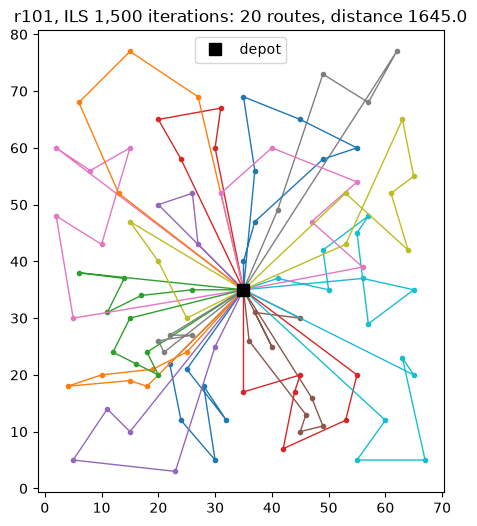

In [11]:
def plot_routes(inst, sol, title):
    fig, ax = plt.subplots(figsize=(6, 6))
    for r in sol.as_lists():
        xs = [inst.x[0]] + [inst.x[c] for c in r] + [inst.x[0]]
        ys = [inst.y[0]] + [inst.y[c] for c in r] + [inst.y[0]]
        ax.plot(xs, ys, marker="o", markersize=3, linewidth=1)
    ax.plot(inst.x[0], inst.y[0], "ks", markersize=9, label="depot")
    ax.set_title(title)
    ax.legend()
    ax.set_aspect("equal")
    plt.show()

plot_routes(inst, sol, f"r101, ILS 1,500 iterations: {sol.n_routes()} routes, distance {sol.distance():.1f}")

## 4. Experimental study

### 4.1 Experimental design
| Factor | Values |
|---|---|
| Instances | the **56 Solomon instances** (100 customers each), in 6 classes: customers **C**lustered, **R**andom, or mixed (**RC**); series **1** has tight time windows and small trucks, series **2** wide windows and large trucks |
| Variants | HC, VND, ILS (60 s per run) |
| Repetitions | 3 runs per instance and variant (seeds 0, 1, 2), since the method is random |
| Instance size | 25, 50 and 100 customers (the first customers of 12 instances, 2 per class) |
| Parameter | perturbation size: remove 2–5, 5–15 or 15–30 customers (12 instances, 2 runs, 30 s) |

**Measures.** Gap to the best known solution, $\text{gap} = 100 \times \frac{\text{our distance} - \text{BKS distance}}{\text{BKS distance}}$ (BKS from SINTEF), number of trucks compared with the fleet $k$, and computation time.

**Note on the reference values.** The BKS minimize the number of trucks **first** and the distance second. Using one more truck usually shortens the distance, so a solution that exceeds the fleet can show a low or even negative gap without being better. We therefore always report whether the fleet limit is respected. In the C2 series, the files allow $k=4$ trucks while the BKS uses 3.

All runs were made with `python experiments.py all` (Python 3.14, Apple laptop, 10 cores in parallel); the cells below only read the saved results.

In [12]:
RESULTS = Path("results")
variants = pd.DataFrame(json.load(open(RESULTS / "variants.json")))
main = pd.DataFrame(json.load(open(RESULTS / "main.json")))
size = pd.DataFrame(json.load(open(RESULTS / "size.json")))
sensitivity = pd.DataFrame(json.load(open(RESULTS / "sensitivity.json")))
runs = pd.concat([variants, main], ignore_index=True)
runs["extra_trucks"] = runs["routes"] - runs["bks_routes"]
CLASSES = ["C1", "C2", "R1", "R2", "RC1", "RC2"]
METHODS = ["hc", "vnd", "ils"]
print(f"{len(runs)} runs on {runs.instance.nunique()} instances; "
      f"all solutions feasible for capacity and time windows: {runs.feasible.all()}")


def scores(d):
    """Quality measures of a group of runs; the gap is only meaningful when the fleet is respected."""
    ok = d[d.fleet_ok]
    return pd.Series({
        "fleet respected (%)": 100 * d.fleet_ok.mean(),
        "gap, fleet respected (%)": ok.gap.mean() if len(ok) else float("nan"),
        "worst gap, fleet respected (%)": ok.gap.max() if len(ok) else float("nan"),
        "extra trucks vs BKS": d.extra_trucks.mean(),
        "mean time (s)": d.time.mean(),
    })

504 runs on 56 instances; all solutions feasible for capacity and time windows: True


### 4.2 From plain hill climbing to ILS

,fleet respected (%),"gap, fleet respected (%)","worst gap, fleet respected (%)",extra trucks vs BKS,mean time (s)
method,,,,,
hc,28.57,41.65,103.27,1.74,0.01
vnd,32.14,15.56,83.47,1.42,0.03
ils,52.98,1.48,13.98,0.54,60.00


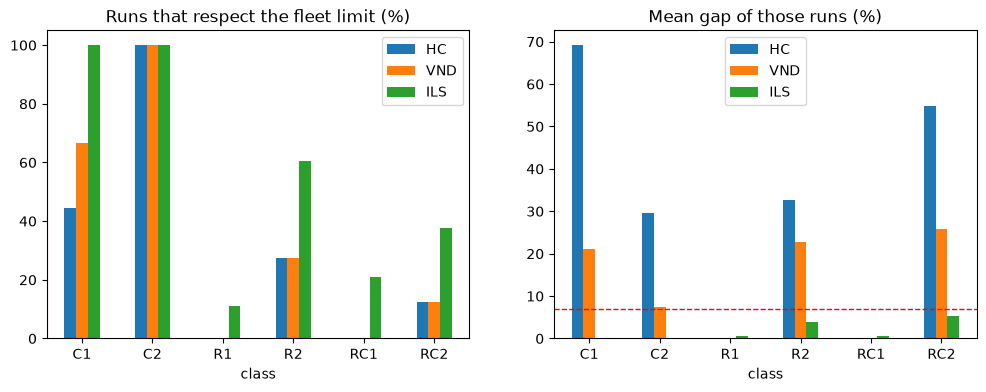

In [13]:
display(runs.groupby("method").apply(scores, include_groups=False).loc[METHODS].round(2))

by_class = runs.groupby(["class", "method"]).apply(scores, include_groups=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
by_class["fleet respected (%)"].unstack().loc[CLASSES, METHODS].plot.bar(ax=axes[0], rot=0)
by_class["gap, fleet respected (%)"].unstack().loc[CLASSES, METHODS].plot.bar(ax=axes[1], rot=0)
axes[0].set_title("Runs that respect the fleet limit (%)")
axes[1].set_title("Mean gap of those runs (%)")
axes[0].legend(["HC", "VND", "ILS"])
axes[1].legend(["HC", "VND", "ILS"], loc="upper center")
axes[1].axhline(7, color="red", linestyle="--", linewidth=1)
plt.show()

Each step pays off:
- **Plain hill climbing** stops at poor local optima in a few milliseconds: it uses on average 1.7 trucks more than the best known solutions and respects the fleet in only 29% of the runs, with a gap of about 42% when it does.
- **VND** (three neighbourhoods) cuts the gap by more than half at almost no extra cost, but still keeps too many trucks.
- **ILS** respects the fleet in 53% of the runs, and those runs have a mean gap of **1.5%**, far below the 7% threshold. All C1 and C2 runs reach the best known solution.

A missing bar on the right means that no run of this variant respected the fleet in this class. The red line is the 7% threshold of the evaluation.

### 4.3 ILS results in detail

,fleet respected (%),"gap, fleet respected (%)","worst gap, fleet respected (%)",extra trucks vs BKS,mean time (s)
class,,,,,
C1,100.00,0.00,0.00,0.00,60.00
C2,100.00,-0.00,0.00,0.00,60.00
R1,11.11,0.70,2.80,0.97,60.01
R2,60.61,3.86,8.79,0.39,60.00
RC1,20.83,0.62,2.15,1.17,60.01
RC2,37.50,5.37,13.98,0.62,60.00


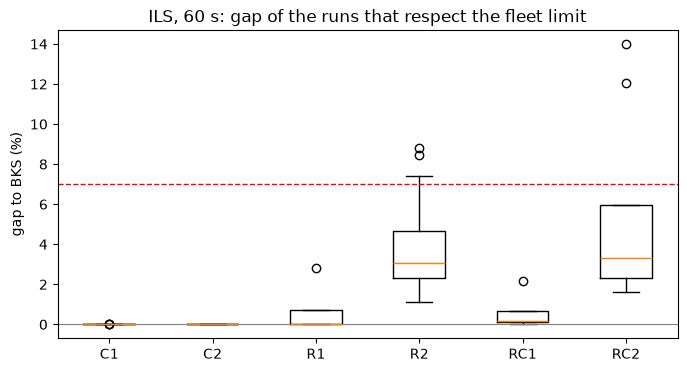

In [14]:
ils = runs[runs.method == "ils"].copy()
display(ils.groupby("class").apply(scores, include_groups=False).loc[CLASSES].round(2))

fig, ax = plt.subplots(figsize=(8, 4))
ok = ils[ils.fleet_ok]
ax.boxplot([ok[ok["class"] == c].gap for c in CLASSES], tick_labels=CLASSES)
ax.axhline(0, color="grey", linewidth=0.8)
ax.axhline(7, color="red", linestyle="--", linewidth=1)
ax.set_ylabel("gap to BKS (%)")
ax.set_title("ILS, 60 s: gap of the runs that respect the fleet limit")
plt.show()

The table below gives every instance (best and mean of the 3 runs). A negative gap always comes with more trucks than the best known solution: one more truck makes routes shorter, so these runs are not better than the reference, they are a different trade-off.

In [15]:
per_instance = ils.groupby("instance").agg(
    cls=("class", "first"), k=("k", "first"), bks_routes=("bks_routes", "first"), bks=("bks_distance", "first"),
    best_routes=("routes", "min"), best_distance=("distance", "min"), mean_gap=("gap", "mean"),
    std_gap=("gap", "std"), fleet_ok_runs=("fleet_ok", "sum"),
).reset_index()
per_instance["sort"] = per_instance.cls.map({c: i for i, c in enumerate(CLASSES)})
per_instance = per_instance.sort_values(["sort", "instance"]).drop(columns="sort")
pd.set_option("display.max_rows", 60)
per_instance.round(2)

,instance,cls,k,bks_routes,bks,best_routes,best_distance,mean_gap,std_gap,fleet_ok_runs
0,c101,C1,10,10,828.94,10,828.94,-0.00,0.00,3
1,c102,C1,10,10,828.94,10,828.94,-0.00,0.00,3
2,c103,C1,10,10,828.06,10,828.06,0.00,0.00,3
3,c104,C1,10,10,824.78,10,824.78,-0.00,0.00,3
4,c105,C1,10,10,828.94,10,828.94,-0.00,0.00,3
5,c106,C1,10,10,828.94,10,828.94,-0.00,0.00,3
6,c107,C1,10,10,828.94,10,828.94,-0.00,0.00,3
7,c108,C1,10,10,828.94,10,828.94,-0.00,0.00,3
8,c109,C1,10,10,828.94,10,828.94,-0.00,0.00,3
9,c201,C2,4,3,591.56,3,591.56,-0.00,0.00,3


### 4.4 Quality over time

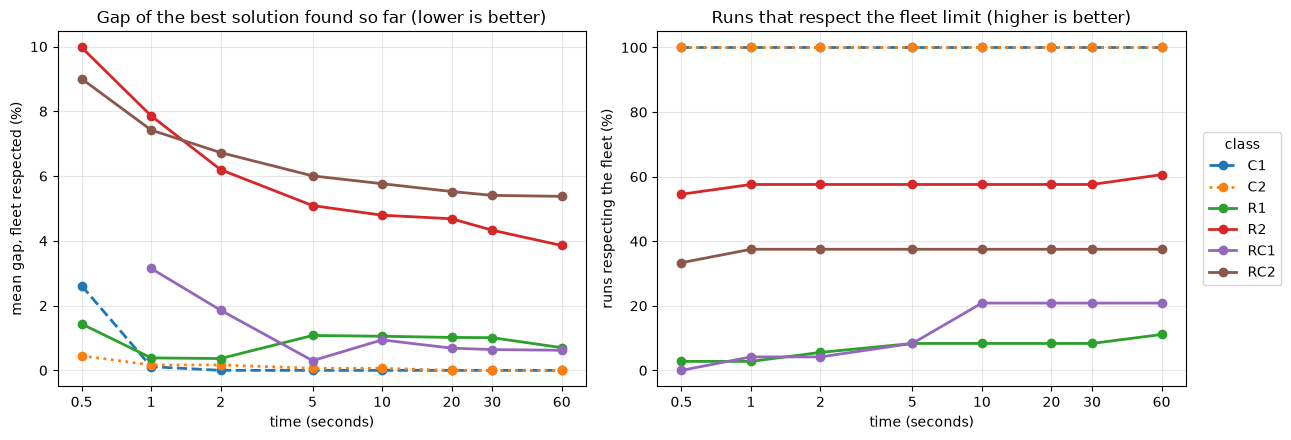

t,0.5,1.0,2.0,5.0,10.0,20.0,30.0,60.0
fleet respected (%),46.43,48.21,48.81,50.00,51.79,51.79,51.79,52.98
"gap, fleet respected (%)",4.29,2.80,2.25,1.86,1.75,1.67,1.58,1.48


In [16]:
def gap_at(row, t):
    """Gap and fleet status of the best solution found by time t in a run."""
    entries = [h for h in row["history"] if h[0] <= t] or row["history"][:1]
    _, distance, routes = entries[-1]
    return 100 * (distance - row["bks_distance"]) / row["bks_distance"], routes <= row["k"]

times = [0.5, 1, 2, 5, 10, 20, 30, 60]
curve = []
for t in times:
    for _, row in ils.iterrows():
        g, ok = gap_at(row, t)
        curve.append({"t": t, "class": row["class"], "gap": g, "fleet_ok": ok})
curve = pd.DataFrame(curve)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
styles = {"C1": "--", "C2": ":"}
for c in CLASSES:
    sub = curve[curve["class"] == c]
    style = dict(marker="o", linestyle=styles.get(c, "-"), linewidth=2, label=c)
    axes[0].plot(times, sub[sub.fleet_ok].groupby("t").gap.mean().reindex(times), **style)
    axes[1].plot(times, 100 * sub.groupby("t").fleet_ok.mean(), **style)
for ax, label in zip(axes, ["mean gap, fleet respected (%)", "runs respecting the fleet (%)"]):
    ax.set_xscale("log")
    ax.set_xticks(times)
    ax.set_xticklabels([f"{t:g}" for t in times])
    ax.minorticks_off()
    ax.set_xlabel("time (seconds)")
    ax.set_ylabel(label)
    ax.grid(alpha=0.3)
axes[1].set_ylim(-5, 105)
axes[0].set_title("Gap of the best solution found so far (lower is better)")
axes[1].set_title("Runs that respect the fleet limit (higher is better)")
axes[1].legend(title="class", loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.tight_layout()
plt.show()
overall_curve = pd.DataFrame({
    "fleet respected (%)": 100 * curve.groupby("t").fleet_ok.mean(),
    "gap, fleet respected (%)": curve[curve.fleet_ok].groupby("t").gap.mean(),
}).T
display(overall_curve.round(2))

The gap curve of a class can go up when a run reaches the fleet limit late and joins the average with a still-high gap (R1 at 5 s). Most of the progress happens in the first seconds: after 5 s, half of the runs already respect the fleet with a mean gap below 2%. The last 55 s only bring small improvements, which suggests that the search stagnates rather than lacks time.

### 4.5 Computation time and instance size

method,ils,vnd,ILS ms per iteration
n,,,
25,0.248,0.002,1.242
50,0.544,0.006,2.720
100,1.225,0.030,6.124


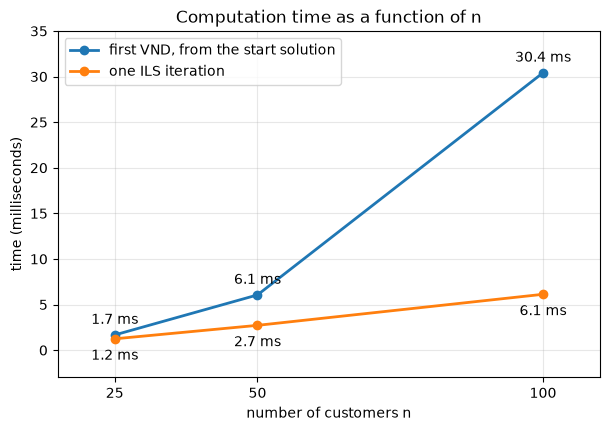

In [17]:
size["per_iteration_ms"] = 1000 * size["time"] / size["iterations"].where(size["iterations"] > 0)
by_size = size.groupby(["n", "method"]).time.mean().unstack()
by_size["ILS ms per iteration"] = size[size.method == "ils"].groupby("n").per_iteration_ms.mean()
display(by_size.round(3))

fig, ax = plt.subplots(figsize=(7, 4.5))
for values, label, offset in [(1000 * by_size["vnd"], "first VND, from the start solution", 8),
                              (by_size["ILS ms per iteration"], "one ILS iteration", -15)]:
    ax.plot(by_size.index, values, marker="o", linewidth=2, label=label)
    for n, v in zip(by_size.index, values):
        ax.annotate(f"{v:.1f} ms", (n, v), textcoords="offset points", xytext=(0, offset), ha="center")
ax.set_xticks(by_size.index)
ax.set_xlim(15, 110)
ax.set_ylim(-3, 35)
ax.set_xlabel("number of customers n")
ax.set_ylabel("time (milliseconds)")
ax.set_title("Computation time as a function of n")
ax.grid(alpha=0.3)
ax.legend(loc="upper left")
plt.show()

One ILS iteration takes about 1.2 ms for 25 customers, 2.7 ms for 50 and 6.1 ms for 100: doubling $n$ multiplies the time by about 2.2, so it grows slightly faster than linearly, thanks to the 20-nearest-neighbour restriction. The first VND, which starts from the greedy solution and includes building it, grows faster (about ×4 per doubling, close to quadratic) because the greedy insertion scans every position for every customer. For several thousand customers, the time limit would have to grow with $n$, and the code would need to be compiled (for example with `numba`).

### 4.6 Robustness and sensitivity to the perturbation size

In [18]:
spread = ils[ils.fleet_ok].groupby(["class", "instance"]).gap.std().groupby("class").mean().loc[CLASSES]
print("Standard deviation of the gap between runs of the same instance (fleet respected), by class:")
display(spread.round(2).to_frame("std of gap (points)").T)

sensitivity["extra_trucks"] = sensitivity["routes"] - sensitivity["bks_routes"]
sens = sensitivity.groupby("removal").apply(scores, include_groups=False)
sens["iterations in 30 s"] = sensitivity.groupby("removal").iterations.mean()
sens.loc[["2-5", "5-15", "15-30"]].round(2)

Standard deviation of the gap between runs of the same instance (fleet respected), by class:


class,C1,C2,R1,R2,RC1,RC2
std of gap (points),0.0,0.0,0.0,1.96,0.91,3.8


,fleet respected (%),"gap, fleet respected (%)","worst gap, fleet respected (%)",extra trucks vs BKS,mean time (s),iterations in 30 s
removal,,,,,,
2-5,58.33,2.35,11.37,0.75,30.01,4276.33
5-15,62.50,1.16,7.38,0.50,30.01,3128.04
15-30,70.83,1.13,5.94,0.29,30.02,2415.62


- **Robustness.** On C1, C2 and R1, the runs that respect the fleet give the same distance for all seeds. The spread is larger on wide-window classes (about 2 points on R2 and 4 points on RC2), where long routes leave more room for different local optima.
- **Perturbation size.** Removing more customers helps to reduce the fleet: 71% of runs respect it with 15–30 removed customers, against 58% with 2–5, for the same gap (about 1.1%). Small perturbations are faster but too weak to escape. This was measured on 12 instances with 2 runs each, so it is an indication rather than a proof; the default (5–15) was kept for the main study.

## 5. Analysis

### 5.1 Strengths
- **Each layer pays off.** Plain hill climbing (gap of about 42% when it respects the fleet), then VND, then ILS (1.5%): this shows concretely why hill climbing alone is not enough. It stops at the first local optimum, and the perturbations are what let ILS escape.
- **Distance is optimized well.** When ILS reaches the right number of trucks, the mean gap is 1.5%, and every C1 and C2 run reaches the best known solution.
- **Fast.** Constant-time feasibility checks and the 20-nearest-neighbour restriction make one ILS iteration take a few milliseconds in pure Python, so most of the quality is reached within 5 seconds.

### 5.2 Limitations
- **Reducing the number of trucks is the main weakness.** The instance files set the fleet to the best known number of trucks, which is very tight. ILS respects it in all C runs but only in 11% of R1 runs, 21% of RC1, 38% of RC2 and 61% of R2, usually missing by one truck. Our objective treats the fleet only through a penalty and removes routes by greedy reinsertion, which often fails when time windows are tight. A quick test of an "ejection" variant (a customer that fits nowhere replaces a nearby one) made iterations much slower without clearly reducing the fleet in 30 s, so it was not kept.
- **Long routes are optimized less well.** The worst runs that respect the fleet (gaps of 7–14%) are on wide-window instances (R2, RC2), whose routes have about 30 customers. Our moves inside a route are limited to relocating one customer.
- **Better-only acceptance stagnates.** The convergence curves flatten after about 5 s: the search spends the remaining time near the same local optimum.
- **Size.** All benchmark instances have 100 customers. The time per iteration grows slightly faster than $n$, so thousands of customers would need compiled code and a time limit adapted to the size.
- **Static travel times.** The benchmark has no traffic. In our model, travel times depend on the departure slot; the solver would need `dist[a][b]` replaced by a function of the departure time in the time computations. The earliest/latest-time check still works under FIFO, but this is not implemented yet.
- **Instance reader.** The instances provided are in Cordeau's text format, which the `vrplib` library does not read, so a small custom reader is used.

### 5.3 Improvements, based on these observations
- **Larger or adaptive perturbations** when the fleet is too large: the sensitivity test already shows a higher fleet success rate with 15–30 removed customers.
- **An acceptance criterion that sometimes keeps a worse solution** (simulated-annealing style, or "accept if within 1% of the best") against the stagnation seen after 5 s.
- **Intra-route moves** (2-opt, moving chains of 2–3 customers) for the long routes of R2 and RC2.
- **A dedicated route-minimization phase** before optimizing distance, as in Nagata & Bräysy (2009).

### 5.4 Conclusion
Plain hill climbing is fast but weak. Turned into an Iterated Local Search with three neighbourhoods and a ruin-and-recreate perturbation, it finds solutions within 1.5% of the best known distance whenever it reaches the right number of trucks, which it always does on clustered instances. Its weak point is minimizing the number of trucks on random instances with tight time windows. This is the criterion to compare most carefully with the ant colony and genetic algorithms of the team.

## References
- Lourenço, H. R., Martin, O. C., & Stützle, T. (2003). Iterated local search. In F. Glover & G. A. Kochenberger (Eds.), *Handbook of Metaheuristics* (pp. 320–353). Springer.
- Nagata, Y., & Bräysy, O. (2009). A powerful route minimization heuristic for the vehicle routing problem with time windows. *Operations Research Letters*, 37(5), 333–338.
- Savelsbergh, M. W. P. (1992). The vehicle routing problem with time windows: Minimizing route duration. *ORSA Journal on Computing*, 4(2), 146–154.
- Solomon, M. M. (1987). Algorithms for the vehicle routing and scheduling problems with time window constraints. *Operations Research*, 35(2), 254–265.
- Toth, P., & Vigo, D. (2003). The granular tabu search and its application to the vehicle-routing problem. *INFORMS Journal on Computing*, 15(4), 333–346.
- SINTEF. Solomon benchmark, 100 customers: best known solutions. https://www.sintef.no/projectweb/top/vrptw/100-customers/